# From treadmill data to runner insights

**Question.** A watch records heart rate and speed. What can that tell a runner that is actually useful, beyond
the raw numbers?

**Data.** 992 maximal treadmill tests from the University of Málaga exercise lab (PhysioNet). Each test
records heart rate, oxygen uptake (VO₂), CO₂ output and treadmill speed for every breath, from a walking
warm-up to exhaustion, for 857 amateur and professional athletes aged 10 to 63.

**What this notebook does**
1. Cleans the raw data and checks it against physiology. This uncovers 51 tests that were run on an
   incline the dataset does not record.
2. Measures **running economy**, the oxygen a runner needs per kilometre. Two runners with the same VO₂max
   can differ a lot here.
3. Tests how well VO₂max can be estimated from data a watch has (heart rate, speed, age, body size),
   checked on people the model has never seen.
4. Turns the numbers for one runner into plain-language feedback.

Run `python3 download_data.py` first.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="Unable to import Axes3D")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_score

from fitness import load_raw, clean_measurements, extract_features, compare_feature_sets
from fitness.features import INCLINE_RATIO_MAX

pd.set_option("display.precision", 2)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#222222", "#6b6b6b"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.edgecolor": "#9a9a9a", "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10})

## 1. Load and clean

In [2]:
meas, subjects = load_raw()
print(f"{len(meas):,} breath-by-breath rows, {meas.ID_test.nunique()} tests, {meas.ID.nunique()} participants")
meas.head()

575,087 breath-by-breath rows, 992 tests, 857 participants


,time,Speed,HR,VO2,VCO2,RR,VE,ID_test,ID
0,0,5.0,63.0,478.0,360.0,27,13.3,2_1,2
1,2,5.0,75.0,401.0,295.0,23,10.3,2_1,2
2,4,5.0,82.0,449.0,319.0,29,12.2,2_1,2
3,7,5.0,87.0,461.0,340.0,28,12.8,2_1,2
4,9,5.0,92.0,574.0,417.0,28,14.6,2_1,2


The raw values contain sensor artefacts: heart rate 0, negative VO₂, and 30 tests without gas data.
`clean_measurements` sets impossible values to NaN rather than dropping rows, so that time and speed stay
intact. It also splits each test into the exercise phase (up to top speed) and recovery.

In [3]:
clean = clean_measurements(meas)
missing = pd.DataFrame({"raw: missing or invalid": [meas.HR.isna().mean() + (meas.HR <= 0).mean(),
                                                     meas.VO2.isna().mean() + (meas.VO2 < 100).mean()],
                        "after cleaning: NaN": [clean.HR.isna().mean(), clean.VO2.isna().mean()]},
                       index=["HR", "VO2"])
(missing * 100).round(2).astype(str) + " %"

,raw: missing or invalid,after cleaning: NaN
HR,0.17 %,0.19 %
VO2,0.85 %,0.85 %


Every test then becomes one row of features (about a minute of computation). The definitions are in
`fitness/features.py`:
- **VO₂max**: peak 30-s average of oxygen uptake per kg.
- **Max heart rate**: peak 5-s average.
- **Walking heart rate** during the warm-up.
- **Speed at 75 % and 85 % of max heart rate**: read directly when heart rate first reaches that level, not
  extrapolated.
- **Running economy**.
- A **level-running check**.

In [4]:
feat = extract_features(clean, subjects)
feat["ramp"] = (feat.protocol == "ramp").astype(int)
print(feat.protocol.value_counts().to_string())
feat.describe().T[["count", "mean", "50%", "min", "max"]]

protocol
ramp    667
step    325


,count,mean,50%,min,max
ID,992.0,424.89,428.50,1.00,857.00
age,992.0,28.98,27.10,10.80,63.00
sex,992.0,0.15,0.00,0.00,1.00
mass,992.0,73.38,73.00,41.00,135.00
height,992.0,174.91,175.00,150.00,203.00
bmi,992.0,23.89,23.67,16.98,43.09
vmax,992.0,16.26,16.70,7.00,23.10
vo2max,981.0,46.95,47.10,21.28,81.77
hrmax,992.0,187.23,187.00,153.00,222.60
hrmax_age,992.0,187.71,189.03,163.90,200.44


## 2. A hidden confound: some tests were run uphill

Physiology gives a check. On a level treadmill the oxygen cost of running is set mostly by speed, and the
ACSM equation predicts it (VO₂ = 3.5 + 0.2 × speed in m/min). For each test I divide the measured cost at
8–11 km/h by that prediction.

The 60-s step tests and the ramp tests sit tightly around 0.9; the ACSM equation is known to overestimate
trained runners by about 10 %. One group of 30-s step tests sits at 1.3–1.8. They need far more oxygen
than their speed explains, almost certainly because the treadmill was inclined. The dataset does not
record incline.

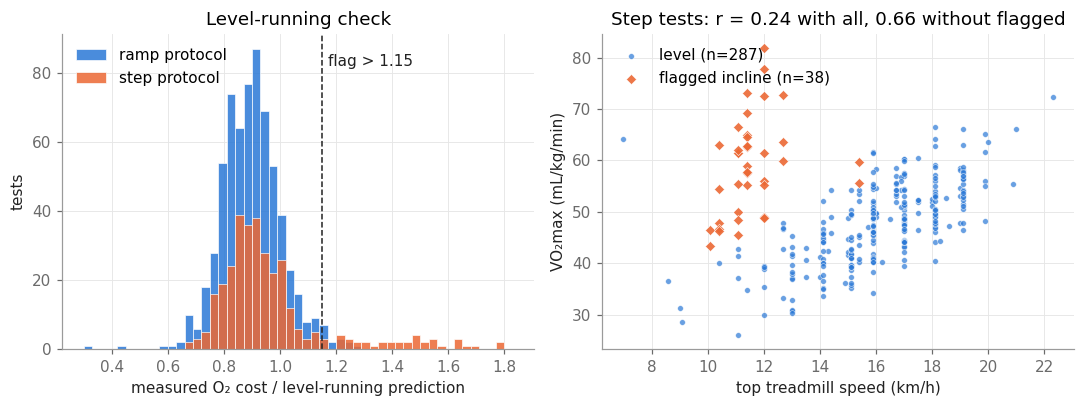

Flagged as incline: 51 of 992 tests


In [5]:
step = feat[feat.protocol == "step"].dropna(subset=["vo2max"])
r_all = step[["vmax", "vo2max"]].corr().iloc[0, 1]
r_lvl = step[step.level][["vmax", "vo2max"]].corr().iloc[0, 1]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
bins = np.arange(0.3, 1.85, 0.03)
for prot, colour in (("ramp", BLUE), ("step", ORANGE)):
    ax[0].hist(feat.loc[feat.protocol == prot, "incline_ratio"].dropna(), bins=bins, color=colour,
               alpha=0.85, label=f"{prot} protocol", edgecolor="white", linewidth=0.5)
ax[0].axvline(INCLINE_RATIO_MAX, color=INK, lw=1, ls="--")
ax[0].text(INCLINE_RATIO_MAX + 0.02, ax[0].get_ylim()[1] * 0.9, f"flag > {INCLINE_RATIO_MAX}", color=INK)
ax[0].set(xlabel="measured O₂ cost / level-running prediction", ylabel="tests",
          title="Level-running check")
ax[0].legend(frameon=False)

lv = step[step.level]; fl = step[~step.level]
ax[1].scatter(lv.vmax, lv.vo2max, s=14, color=BLUE, alpha=0.7, edgecolor="white", linewidth=0.4,
              label=f"level (n={len(lv)})")
ax[1].scatter(fl.vmax, fl.vo2max, s=22, color=ORANGE, alpha=0.9, edgecolor="white", linewidth=0.4,
              marker="D", label=f"flagged incline (n={len(fl)})")
ax[1].set(xlabel="top treadmill speed (km/h)", ylabel="VO₂max (mL/kg/min)",
          title=f"Step tests: r = {r_all:.2f} with all, {r_lvl:.2f} without flagged")
ax[1].legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig("figures/incline_check.png", bbox_inches="tight"); plt.show()
print(f"Flagged as incline: {(~feat.level).sum()} of {len(feat)} tests")

Removing the flagged tests raises the correlation between top speed and VO₂max in step tests from 0.24
to 0.66, close to the ramp tests. Without this check, every later model would learn from
tests where "slow but very fit" is an artefact of the hill. **All analyses below use level tests only.**

## 3. Running economy: the same engine, different fuel use

Running economy is the oxygen used per kilogram per kilometre. Lower is better: the runner covers the same
distance with less energy. I measure it only where it is clean:
- 60-s step tests, using the last 15 s of each stage at 9–13 km/h;
- only while RER < 1, so the oxygen uptake still reflects the aerobic cost.

That leaves 162 tests.

In [6]:
eco = feat[feat.economy.notna() & feat.level].copy()
print(f"{len(eco)} tests, {eco.ID.nunique()} people. Median {eco.economy.median():.0f} mL/kg/km, "
      f"10-90 % range {eco.economy.quantile(.1):.0f}-{eco.economy.quantile(.9):.0f}")
band = eco[eco.vo2max.between(50, 55)]
eco["capacity_at_12"] = eco.economy * 12 / 60 / eco.vo2max   # fraction of VO2max used at 12 km/h
lo, hi = band.economy.quantile([.1, .9])
ulo, uhi = (band.economy.quantile([.1, .9]) * 12 / 60 / band.vo2max.median())
print(f"Runners with VO2max 50-55 (n={len(band)}): economy {lo:.0f} to {hi:.0f} mL/kg/km (10th-90th pct.)")
print(f"-> at 12 km/h (5:00 min/km) they use about {ulo:.0%} versus {uhi:.0%} of their VO2max")

162 tests, 152 people. Median 205 mL/kg/km, 10-90 % range 187-226
Runners with VO2max 50-55 (n=42): economy 193 to 222 mL/kg/km (10th-90th pct.)
-> at 12 km/h (5:00 min/km) they use about 74% versus 85% of their VO2max


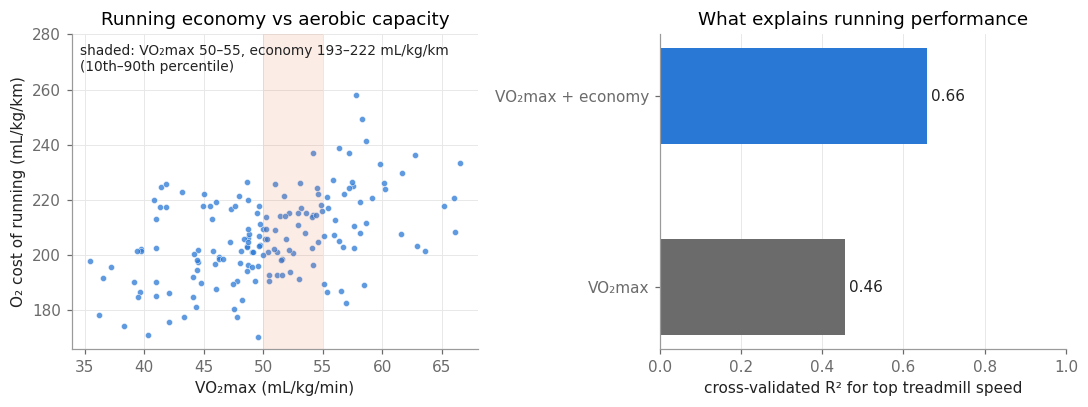

{'VO₂max': 0.45712362740424106, 'VO₂max + economy': 0.6569445384266073}

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(eco.vo2max, eco.economy, s=16, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.4)
ax[0].axvspan(50, 55, color=ORANGE, alpha=0.12, lw=0)
ax[0].text(0.02, 0.97, f"shaded: VO₂max 50–55, economy {lo:.0f}–{hi:.0f} mL/kg/km\n(10th–90th percentile)",
           transform=ax[0].transAxes, va="top", color=INK, fontsize=9)
ax[0].set(xlabel="VO₂max (mL/kg/min)", ylabel="O₂ cost of running (mL/kg/km)",
          title="Running economy vs aerobic capacity")
ax[0].set_ylim(top=eco.economy.max() + 22)

cv = GroupKFold(5)
r2 = {}
for name, cols in {"VO₂max": ["vo2max"], "VO₂max + economy": ["vo2max", "economy"]}.items():
    r2[name] = cross_val_score(LinearRegression(), eco[cols], eco.vmax, groups=eco.ID, cv=cv,
                               scoring="r2").mean()
bars = ax[1].barh(list(r2), list(r2.values()), color=[MUTED, BLUE], height=0.5)
for b, v in zip(bars, r2.values()):
    ax[1].text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", color=INK)
ax[1].set(xlim=(0, 1), xlabel="cross-validated R² for top treadmill speed",
          title="What explains running performance")
ax[1].grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("figures/running_economy.png", bbox_inches="tight"); plt.show()
r2

**What this means for a runner**
- Running economy varies by about ±7 % between runners of the same VO₂max. At an everyday 5:00 min/km
  pace, that is the difference between running at about 74 % and about 85 % of capacity.
- Top speed (a performance proxy) is explained much better by VO₂max **and** economy together than by
  VO₂max alone (cross-validated R² 0.66 against 0.46). An app that reports only VO₂max misses a large
  part of the story.
- Economy and VO₂max are positively correlated here (r ≈ 0.47): the fittest runners are not the most
  economical per kg. Running studies have reported this trade-off. It is partly a scaling effect too, since
  both quantities are divided by body mass, and lighter runners have a higher cost per kg.

## 4. Can VO₂max be estimated from what a watch measures?

A watch does not measure oxygen. It has heart rate, speed, the user's profile, and sometimes a known
maximum heart rate. I compare ridge-regression models with increasing information:

| Feature set | Contents |
|---|---|
| demographics | age, sex, body mass, height, BMI, protocol |
| + HR (age-formula max HR) | walking HR, and the speeds at 75 % and 85 % of max HR, with max HR from the formula 208 − 0.7 × age |
| + HR (true max HR) | the same, using the runner's measured max HR, as a watch can learn from hard sessions |
| + peak speed | top speed of a maximal test; an upper reference, since it needs an all-out effort |

**Validation:** 5-fold cross-validation with folds **grouped by participant**. People with repeat tests
never appear in both training and test folds; otherwise the model could simply recognise them.

In [8]:
demo = ["age", "sex", "bmi", "mass", "height", "ramp"]
sets = {"demographics": demo,
        "+ HR (age-formula max HR)": demo + ["hr_walk", "v_hr75_age", "v_hr85_age"],
        "+ HR (true max HR)": demo + ["hr_walk", "v_hr75_true", "v_hr85_true"],
        "+ peak speed (max test)": demo + ["vmax"]}
cols = sorted(set(sum(sets.values(), [])))
d = feat[feat.level].dropna(subset=cols + ["vo2max"]).reset_index(drop=True)
print(f"{len(d)} tests from {d.ID.nunique()} people")
table, preds = compare_feature_sets(d, "vo2max", sets)
table

877 tests from 755 people


,n_features,MAE,RMSE,r,within_3.5
features,,,,,
baseline: mean,0,6.74,8.36,-0.07,0.32
demographics,6,5.37,6.78,0.58,0.41
+ HR (age-formula max HR),9,4.89,6.24,0.66,0.46
+ HR (true max HR),9,4.73,6.03,0.69,0.45
+ peak speed (max test),7,4.30,5.50,0.75,0.48


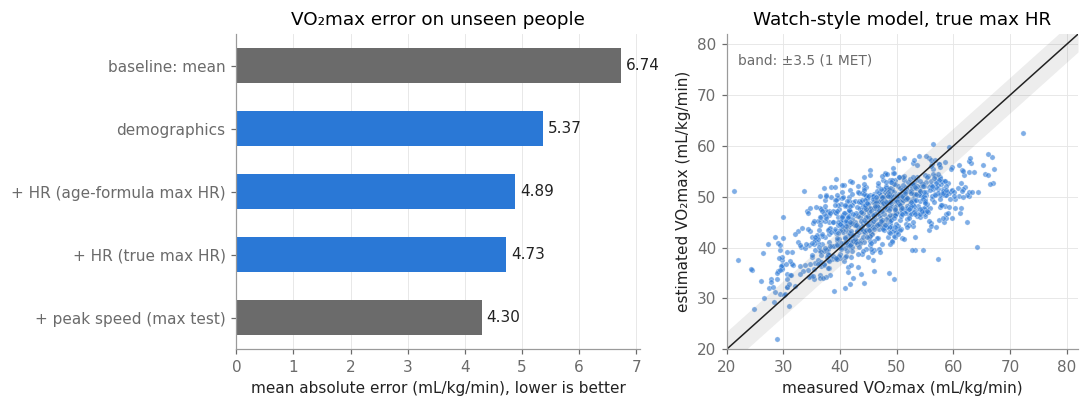

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1.15, 1]})
order = table.index[::-1]
colours = [MUTED if "baseline" in k or "peak" in k else BLUE for k in order]
bars = ax[0].barh(order, table.loc[order, "MAE"], color=colours, height=0.55)
for b, v in zip(bars, table.loc[order, "MAE"]):
    ax[0].text(v + 0.08, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", color=INK)
ax[0].set(xlabel="mean absolute error (mL/kg/min), lower is better",
          title="VO₂max error on unseen people")
ax[0].grid(axis="y", visible=False)

best = "+ HR (true max HR)"
ax[1].scatter(d.vo2max, preds[best], s=12, color=BLUE, alpha=0.6, edgecolor="white", linewidth=0.3)
lim = [20, 82]
ax[1].plot(lim, lim, color=INK, lw=1)
ax[1].fill_between(lim, [l - 3.5 for l in lim], [l + 3.5 for l in lim], color=MUTED, alpha=0.12, lw=0)
ax[1].set(xlim=lim, ylim=lim, xlabel="measured VO₂max (mL/kg/min)", ylabel="estimated VO₂max (mL/kg/min)",
          title="Watch-style model, true max HR")
ax[1].text(22, 76, "band: ±3.5 (1 MET)", color=MUTED, fontsize=9)
fig.tight_layout(); fig.savefig("figures/vo2max_models.png", bbox_inches="tight"); plt.show()

In [10]:
resid = preds[best] - d.vo2max
by_level = pd.cut(d.vo2max, [0, 40, 50, 60, 90])
resid.groupby(by_level, observed=True).agg(["count", "mean"]).rename(columns={"mean": "mean error"})

,count,mean error
vo2max,,
"(0, 40]",200,5.48
"(40, 50]",388,0.90
"(50, 60]",251,-4.21
"(60, 90]",38,-10.61


**Findings**
- Body size, age and sex alone already explain part of VO₂max, with an error of about 5.4 mL/kg/min against
  6.7 for guessing the mean.
- Adding heart rate at known running speeds lowers the error to about 4.9. Using the runner's **true** max
  heart rate instead of the age formula helps further, to about 4.7. The age formula misses individual max
  HR by about 7 bpm on average here, so *knowing your own max heart rate improves the estimate*.
- A maximal test (top speed) is better still, at about 4.3, but no-one does an all-out test every week.
- The model **regresses towards the mean**. It overestimates unfit and underestimates very fit people (see
  the table above). A product would need per-user calibration over many runs, not one session.
- These are short lab ramps. A watch sees many steady runs at varied paces, which should give cleaner
  heart-rate-to-speed relations than one fast ramp. These numbers are a lower bound on what is possible,
  not an estimate of any product's accuracy.

## 5. From numbers to feedback for one runner

The same features, compared with everyone else in the dataset, become advice a person can act on.

In [11]:
def insight(row, pop):
    pct = lambda col, higher_is_better=True: (
        (pop[col] < row[col]).mean() if higher_is_better else (pop[col] > row[col]).mean())
    use12 = row.economy * 12 / 60 / row.vo2max
    lines = [
        f"Aerobic capacity: VO2max {row.vo2max:.0f} mL/kg/min, higher than {pct('vo2max'):.0%} of runners here.",
        f"Running economy: {row.economy:.0f} mL O2 per kg per km, more economical than "
        f"{pct('economy', False):.0%} of runners here.",
        f"At 5:00 min/km you run at about {use12:.0%} of your capacity.",
    ]
    if pct("economy", False) < 0.4 <= pct("vo2max"):
        lines.append("Your engine is strong but you use more fuel per km than most. Technique, strides and "
                     "strength work tend to improve economy; that is your quickest route to faster races.")
    elif pct("vo2max") < 0.4:
        lines.append("Your economy is good; more aerobic volume and interval sessions would raise your "
                     "capacity, which is where your biggest gains are.")
    else:
        lines.append("Capacity and economy are both above average; keep a balanced plan.")
    return "\n".join(lines)

example = eco[(eco.vo2max.between(52, 58))].sort_values("economy").iloc[-3]   # fit but uneconomical
print(f"Runner {example.ID_test} (age {example.age:.0f})\n")
print(insight(example, eco))

Runner 748_1 (age 35)

Aerobic capacity: VO2max 54 mL/kg/min, higher than 70% of runners here.
Running economy: 237 mL O2 per kg per km, more economical than 2% of runners here.
At 5:00 min/km you run at about 88% of your capacity.
Your engine is strong but you use more fuel per km than most. Technique, strides and strength work tend to improve economy; that is your quickest route to faster races.


## 6. Limitations
- **Lab data, not a watch.** The data come from treadmill ramps with a gas analyser and a 12-lead ECG,
  which give cleaner heart rate than a wrist sensor and no GPS or terrain noise.
- **Incline is inferred, not recorded.** The flag uses a physiological threshold, so a few incline tests
  near the threshold may remain, or a few level tests may be removed.
- **Steady state.** 60-s stages are close to, but not fully at, a steady state of oxygen uptake. Economy
  values may be a few percent low. This applies to all runners alike, so the comparisons between runners
  hold.
- **Sample.** Mostly young male athletes (15 % women). Results may not transfer to the general population.
- **Not medical or coaching advice.** The feedback text in section 5 shows the idea of turning numbers into
  messages; physiologists would have to validate the wording and thresholds.